In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving HR_Salary_Fairness_200.csv to HR_Salary_Fairness_200.csv


In [ ]:
df = pd.read_csv('HR_Salary_Fairness_200.csv')

df.head()

,Employee_ID,Designation,Experience,Education,Location,Performance_Score,Salary,Salary_Increment
0,EMP096,Business Analyst,1,Master's,Chennai,4.6,949000,5.3
1,EMP016,Data Analyst,10,Bachelor's,Coimbatore,3.6,1119000,5.5
2,EMP031,UI/UX Designer,6,Bachelor's,Chennai,5.0,1052000,6.3
3,EMP159,Business Analyst,13,Master's,Bangalore,2.8,1867000,3.8
4,EMP129,QA Engineer,5,Master's,Chennai,3.6,950000,3.7


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (200, 8)

Columns:
['Employee_ID', 'Designation', 'Experience', 'Education', 'Location', 'Performance_Score', 'Salary', 'Salary_Increment']

Data Types:
Employee_ID           object
Designation           object
Experience             int64
Education             object
Location              object
Performance_Score    float64
Salary                 int64
Salary_Increment     float64
dtype: object

First 5 Rows:


,Employee_ID,Designation,Experience,Education,Location,Performance_Score,Salary,Salary_Increment
0,EMP096,Business Analyst,1,Master's,Chennai,4.6,949000,5.3
1,EMP016,Data Analyst,10,Bachelor's,Coimbatore,3.6,1119000,5.5
2,EMP031,UI/UX Designer,6,Bachelor's,Chennai,5.0,1052000,6.3
3,EMP159,Business Analyst,13,Master's,Bangalore,2.8,1867000,3.8
4,EMP129,QA Engineer,5,Master's,Chennai,3.6,950000,3.7


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Employee_ID          0
Designation          0
Experience           0
Education            0
Location             0
Performance_Score    0
Salary               0
Salary_Increment     0
dtype: int64


In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [ ]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (200, 8)


In [ ]:
df.columns = df.columns.str.strip().str.replace(' ', '_')

print(df.columns)

Index(['Employee_ID', 'Designation', 'Experience', 'Education', 'Location',
       'Performance_Score', 'Salary', 'Salary_Increment'],
      dtype='object')


In [ ]:
for col in ['Designation', 'Education', 'Location']:
    print(f"\n{col}:")
    print(df[col].unique())


Designation:
['Business Analyst' 'Data Analyst' 'UI/UX Designer' 'QA Engineer'
 'Tech Lead' 'DevOps Engineer' 'Project Manager' 'Software Engineer'
 'Senior Software Engineer' 'HR Executive']

Education:
["Master's" "Bachelor's" 'PhD']

Location:
['Chennai' 'Coimbatore' 'Bangalore' 'Hyderabad' 'Mumbai' 'Pune']


In [ ]:
numeric_cols = [
    'Experience',
    'Performance_Score',
    'Salary',
    'Salary_Increment'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [ ]:
df = df.dropna(subset=[
    'Designation',
    'Experience',
    'Education',
    'Location',
    'Performance_Score',
    'Salary',
    'Salary_Increment'
])

print("Final Shape:", df.shape)

Final Shape: (200, 8)


In [ ]:
df.describe()

,Experience,Performance_Score,Salary,Salary_Increment
count,200.00000,200.000000,2.000000e+02,200.000000
mean,7.39500,3.334000,1.365255e+06,3.820000
std,5.07323,0.788768,4.900459e+05,1.429868
min,0.00000,1.200000,4.270000e+05,0.000000
25%,3.00000,2.800000,9.885000e+05,2.975000
50%,7.00000,3.300000,1.306500e+06,3.800000
75%,12.00000,3.900000,1.632750e+06,4.800000
max,15.00000,5.000000,2.803000e+06,7.800000


In [ ]:
df.describe(include='object')

,Employee_ID,Designation,Education,Location
count,200,200,200,200
unique,200,10,3,6
top,EMP096,QA Engineer,Bachelor's,Coimbatore
freq,1,26,118,39


In [ ]:
designation_salary = df.groupby('Designation')['Salary'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).sort_values('mean', ascending=False)

display(designation_salary)

,count,mean,median,min,max
Designation,,,,,
Project Manager,18,2.045611e+06,2065000.0,1345000,2734000
Tech Lead,19,1.841632e+06,1644000.0,1098000,2803000
Senior Software Engineer,17,1.456176e+06,1367000.0,931000,2070000
DevOps Engineer,23,1.447565e+06,1376000.0,757000,2155000
Business Analyst,19,1.338474e+06,1230000.0,856000,1900000
Data Analyst,20,1.301750e+06,1332000.0,715000,1923000
Software Engineer,23,1.133348e+06,1079000.0,589000,1702000
QA Engineer,26,1.114654e+06,1166500.0,427000,1745000
UI/UX Designer,20,1.114250e+06,1038000.0,664000,1785000


In [ ]:
df['Experience_Group'] = pd.cut(
    df['Experience'],
    bins=[0, 2, 5, 10, 20, 100],
    labels=['0-2', '3-5', '6-10', '11-20', '20+']
)

experience_salary = df.groupby(
    'Experience_Group',
    observed=False
)['Salary'].mean()

display(experience_salary)

,Salary
Experience_Group,
0-2,1.041400e+06
3-5,1.112417e+06
6-10,1.376250e+06
11-20,1.769338e+06
20+,NaN


In [ ]:
location_salary = df.groupby('Location')['Salary'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).sort_values('mean', ascending=False)

display(location_salary)

,count,mean,median,min,max
Location,,,,,
Bangalore,32,1.493188e+06,1441500.0,720000,2803000
Pune,29,1.482483e+06,1402000.0,760000,2734000
Mumbai,33,1.368303e+06,1388000.0,691000,2176000
Chennai,37,1.354514e+06,1261000.0,571000,2572000
Hyderabad,30,1.289867e+06,1179500.0,544000,2099000
Coimbatore,39,1.238718e+06,1119000.0,427000,2317000


In [ ]:
performance_increment = df.groupby(
    'Performance_Score'
)['Salary_Increment'].mean()

display(performance_increment)

,Salary_Increment
Performance_Score,
1.2,0.700000
1.4,1.600000
1.6,0.400000
1.8,1.200000
1.9,1.500000
2.0,1.300000
2.1,2.180000
2.2,1.200000
2.3,2.266667


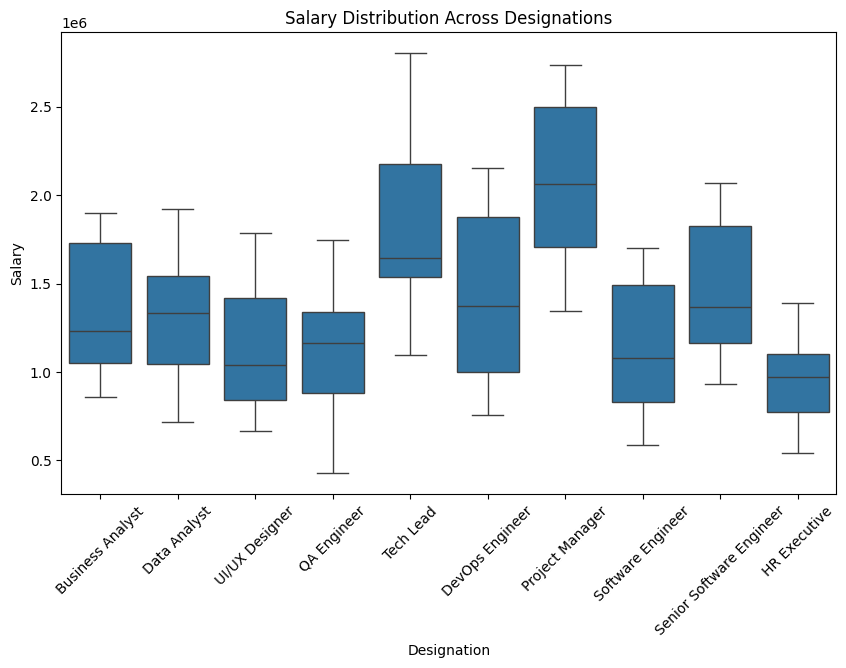

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Designation',
    y='Salary'
)

plt.title('Salary Distribution Across Designations')
plt.xticks(rotation=45)
plt.xlabel('Designation')
plt.ylabel('Salary')

plt.show()

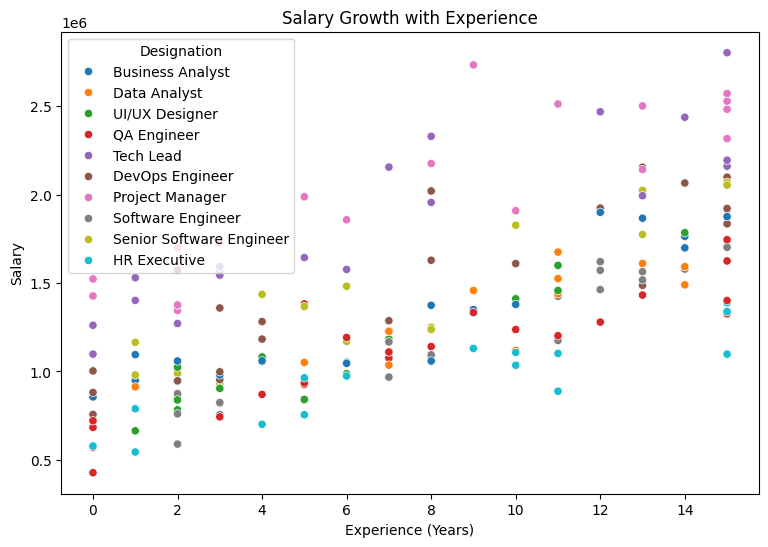

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Experience',
    y='Salary',
    hue='Designation'
)

plt.title('Salary Growth with Experience')
plt.xlabel('Experience (Years)')
plt.ylabel('Salary')

plt.show()

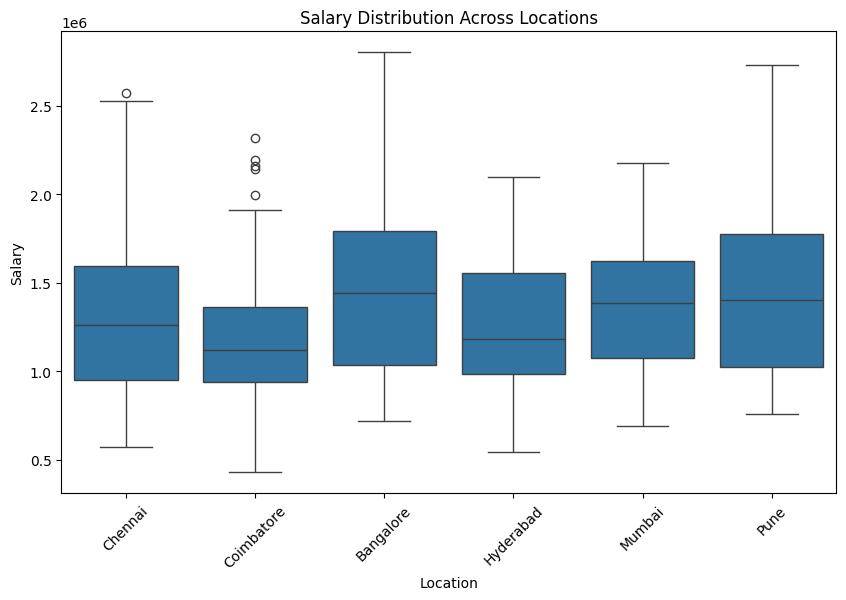

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Location',
    y='Salary'
)

plt.title('Salary Distribution Across Locations')
plt.xlabel('Location')
plt.ylabel('Salary')

plt.xticks(rotation=45)

plt.show()

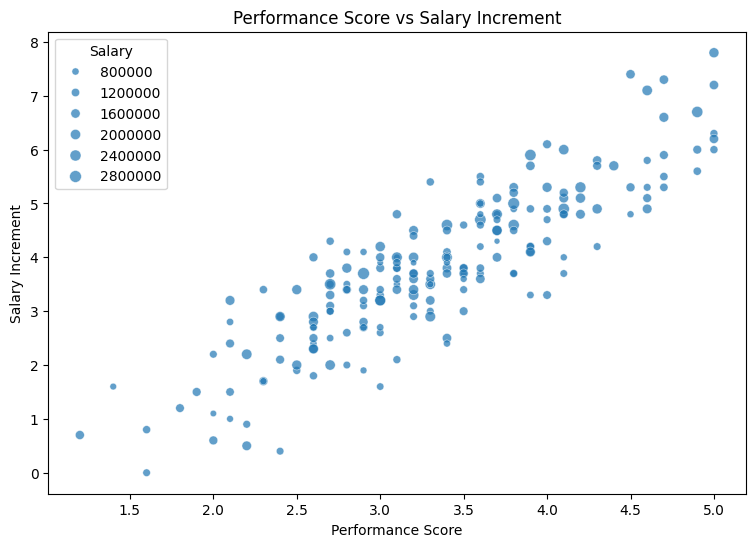

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Performance_Score',
    y='Salary_Increment',
    size='Salary',
    alpha=0.7
)

plt.title('Performance Score vs Salary Increment')
plt.xlabel('Performance Score')
plt.ylabel('Salary Increment')

plt.show()

In [ ]:
df['Peer_Group'] = (
    df['Designation'].astype(str) + '_' +
    df['Experience_Group'].astype(str) + '_' +
    df['Education'].astype(str) + '_' +
    df['Location'].astype(str)
)

df.head()

,Employee_ID,Designation,Experience,Education,Location,Performance_Score,Salary,Salary_Increment,Experience_Group,Peer_Group
0,EMP096,Business Analyst,1,Master's,Chennai,4.6,949000,5.3,0-2,Business Analyst_0-2_Master's_Chennai
1,EMP016,Data Analyst,10,Bachelor's,Coimbatore,3.6,1119000,5.5,6-10,Data Analyst_6-10_Bachelor's_Coimbatore
2,EMP031,UI/UX Designer,6,Bachelor's,Chennai,5.0,1052000,6.3,6-10,UI/UX Designer_6-10_Bachelor's_Chennai
3,EMP159,Business Analyst,13,Master's,Bangalore,2.8,1867000,3.8,11-20,Business Analyst_11-20_Master's_Bangalore
4,EMP129,QA Engineer,5,Master's,Chennai,3.6,950000,3.7,3-5,QA Engineer_3-5_Master's_Chennai


In [ ]:
df['Peer_Average_Salary'] = df.groupby(
    'Peer_Group'
)['Salary'].transform('mean')

df['Salary_Difference'] = (
    df['Salary'] - df['Peer_Average_Salary']
)

df['Salary_Difference_Percent'] = (
    df['Salary_Difference'] /
    df['Peer_Average_Salary']
) * 100

In [ ]:
df['Compensation_Flag'] = np.where(
    df['Salary_Difference_Percent'] > 20,
    'Above Peer Range',
    np.where(
        df['Salary_Difference_Percent'] < -20,
        'Below Peer Range',
        'Within Peer Range'
    )
)

display(
    df[
        [
            'Employee_ID',
            'Designation',
            'Experience',
            'Location',
            'Salary',
            'Peer_Average_Salary',
            'Salary_Difference_Percent',
            'Compensation_Flag'
        ]
    ].sort_values(
        'Salary_Difference_Percent'
    )
)

,Employee_ID,Designation,Experience,Location,Salary,Peer_Average_Salary,Salary_Difference_Percent,Compensation_Flag
129,EMP040,Project Manager,6,Pune,1858000,2.296000e+06,-19.076655,Within Peer Range
175,EMP193,DevOps Engineer,13,Hyderabad,1487000,1.793000e+06,-17.066369,Within Peer Range
105,EMP145,Software Engineer,11,Coimbatore,1175000,1.373500e+06,-14.452130,Within Peer Range
164,EMP064,Business Analyst,8,Pune,1059000,1.216500e+06,-12.946979,Within Peer Range
16,EMP057,Senior Software Engineer,13,Pune,1775000,1.966333e+06,-9.730463,Within Peer Range
...,...,...,...,...,...,...,...,...
166,EMP108,DevOps Engineer,4,Coimbatore,1183000,1.090500e+06,8.482348,Within Peer Range
76,EMP027,Business Analyst,8,Pune,1374000,1.216500e+06,12.946979,Within Peer Range
150,EMP177,Software Engineer,12,Coimbatore,1572000,1.373500e+06,14.452130,Within Peer Range
45,EMP196,DevOps Engineer,15,Hyderabad,2099000,1.793000e+06,17.066369,Within Peer Range


In [ ]:
print(
    df['Compensation_Flag'].value_counts()
)

Compensation_Flag
Within Peer Range    200
Name: count, dtype: int64


In [ ]:
potential_gaps = df[
    df['Compensation_Flag'] != 'Within Peer Range'
].sort_values(
    'Salary_Difference_Percent'
)

display(potential_gaps)

,Employee_ID,Designation,Experience,Education,Location,Performance_Score,Salary,Salary_Increment,Experience_Group,Peer_Group,Peer_Average_Salary,Salary_Difference,Salary_Difference_Percent,Compensation_Flag


In [ ]:
features = [
    'Experience',
    'Designation',
    'Education',
    'Location',
    'Performance_Score',
    'Salary_Increment'
]

X = df[features]
y = df['Salary']

In [ ]:
numeric_features = [
    'Experience',
    'Performance_Score',
    'Salary_Increment'
]

categorical_features = [
    'Designation',
    'Education',
    'Location'
]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [ ]:
model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (160, 6)
Testing Data: (40, 6)


In [ ]:
model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [ ]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred
})

display(comparison.head(10))

,Actual Salary,Predicted Salary
0,544000,4.804030e+05
1,1082000,1.026181e+06
2,1051000,1.037849e+06
3,947000,9.393297e+05
4,842000,8.009139e+05
5,1192000,1.166821e+06
6,1082000,1.044833e+06
7,1745000,1.755234e+06
8,964000,8.695867e+05
9,2099000,1.978512e+06


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

Model Evaluation Results
------------------------
MAE : 85891.41
MSE : 14329335990.79
RMSE: 119705.2
R²  : 0.9197


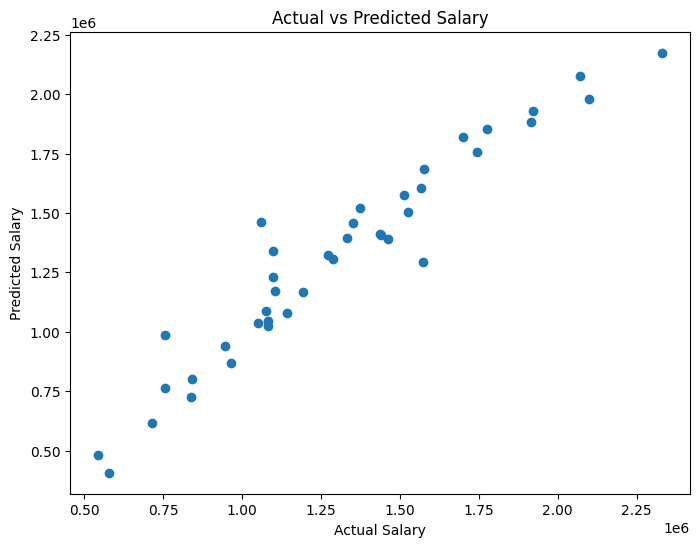

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Salary')
plt.ylabel('Predicted Salary')
plt.title('Actual vs Predicted Salary')

plt.show()

In [ ]:
salary_growth = df.groupby(
    'Experience_Group',
    observed=False
)['Salary'].mean()

growth_percentage = salary_growth.pct_change() * 100

growth_table = pd.DataFrame({
    'Average Salary': salary_growth,
    'Growth %': growth_percentage
})

display(growth_table)

,Average Salary,Growth %
Experience_Group,,
0-2,1.041400e+06,NaN
3-5,1.112417e+06,6.819346
6-10,1.376250e+06,23.717132
11-20,1.769338e+06,28.562270
20+,NaN,0.000000


In [ ]:
performance_analysis = df.groupby(
    'Performance_Score'
).agg(
    Average_Salary=('Salary', 'mean'),
    Average_Increment=('Salary_Increment', 'mean'),
    Employee_Count=('Employee_ID', 'count')
)

display(performance_analysis)

,Average_Salary,Average_Increment,Employee_Count
Performance_Score,,,
1.2,1.482000e+06,0.700000,1
1.4,6.640000e+05,1.600000,1
1.6,1.024500e+06,0.400000,2
1.8,1.326000e+06,1.200000,1
1.9,1.379000e+06,1.500000,1
2.0,9.880000e+05,1.300000,3
2.1,1.176600e+06,2.180000,5
2.2,1.594667e+06,1.200000,3
2.3,1.107667e+06,2.266667,3


In [ ]:
highest_role = designation_salary['mean'].idxmax()
lowest_role = designation_salary['mean'].idxmin()

highest_location = location_salary['mean'].idxmax()
lowest_location = location_salary['mean'].idxmin()

highest_experience_group = experience_salary.idxmax()

highest_performance = performance_increment.idxmax()

above_gap = (
    df['Compensation_Flag'] == 'Above Peer Range'
).sum()

below_gap = (
    df['Compensation_Flag'] == 'Below Peer Range'
).sum()

print("KEY INSIGHTS")
print("============")

print(f"1. {highest_role} has the highest average salary among the observed designations.")

print(f"2. {lowest_role} has the lowest average salary among the observed designations.")

print(f"3. The highest average salary is observed in the {highest_location} location.")

print(f"4. The lowest average salary is observed in the {lowest_location} location.")

print(f"5. The {highest_experience_group} experience group has the highest average salary.")

print(f"6. Performance score {highest_performance} has the highest average salary increment.")

print(f"7. {above_gap} employees are above the selected peer salary threshold and "
      f"{below_gap} employees are below it.")

KEY INSIGHTS
1. Project Manager has the highest average salary among the observed designations.
2. HR Executive has the lowest average salary among the observed designations.
3. The highest average salary is observed in the Bangalore location.
4. The lowest average salary is observed in the Coimbatore location.
5. The 11-20 experience group has the highest average salary.
6. Performance score 5.0 has the highest average salary increment.
7. 0 employees are above the selected peer salary threshold and 0 employees are below it.


In [ ]:
print("PRACTICAL ACTION PLAN")
print("=====================")

print("""
1. Review employees flagged as substantially above or below their peer-group
   average salary.

2. Investigate whether differences are explained by experience, role,
   education, location, or performance.

3. Review salary structures across locations where large differences exist.

4. Compare performance scores with salary increments to check whether
   increments follow the organisation's compensation policy.

5. Conduct periodic compensation reviews using peer-group comparisons.

6. Use the Linear Regression model as a supporting analytical tool,
   not as the sole basis for compensation decisions.

7. Document legitimate reasons for exceptional compensation differences.
""")

PRACTICAL ACTION PLAN

1. Review employees flagged as substantially above or below their peer-group
   average salary.

2. Investigate whether differences are explained by experience, role,
   education, location, or performance.

3. Review salary structures across locations where large differences exist.

4. Compare performance scores with salary increments to check whether
   increments follow the organisation's compensation policy.

5. Conduct periodic compensation reviews using peer-group comparisons.

6. Use the Linear Regression model as a supporting analytical tool,
   not as the sole basis for compensation decisions.

7. Document legitimate reasons for exceptional compensation differences.



In [ ]:
print("HR COMPENSATION ANALYTICS — FINAL SUMMARY")
print("==========================================")

print(f"Total Employees Analysed : {len(df)}")
print(f"Average Salary           : {df['Salary'].mean():.2f}")
print(f"Median Salary            : {df['Salary'].median():.2f}")
print(f"Average Experience       : {df['Experience'].mean():.2f} years")
print(f"Average Performance      : {df['Performance_Score'].mean():.2f}")
print(f"Average Increment        : {df['Salary_Increment'].mean():.2f}")

print("\nLinear Regression Results")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

print("\nPotential Compensation Differences")
print(f"Above Peer Range : {above_gap}")
print(f"Below Peer Range : {below_gap}")

HR COMPENSATION ANALYTICS — FINAL SUMMARY
Total Employees Analysed : 200
Average Salary           : 1365255.00
Median Salary            : 1306500.00
Average Experience       : 7.39 years
Average Performance      : 3.33
Average Increment        : 3.82

Linear Regression Results
MAE  : 85891.41
RMSE : 119705.20
R²   : 0.9197

Potential Compensation Differences
Above Peer Range : 0
Below Peer Range : 0
